# **Muhammad Ibtisam Afzal**

# Assignment 5: Regression and Classification

**Objective:** Build and evaluate regression and classification models using a student-performance dataset.

This notebook completes all five questions:
1. Multivariate Linear Regression with at least three independent variables.
2. Polynomial Regression and comparison with Linear Regression.
3. Binary Logistic Regression to predict Pass/Fail.
4. Multiclass Logistic Regression to classify Low, Medium, and High performance.
5. Comparison of model predictions with actual values.

**Dataset:** A reproducible synthetic dataset of 300 students is generated in this notebook. It contains study hours, attendance, previous exam marks, and assignment marks. The final exam mark is the regression target. Pass/Fail and performance categories are derived from that mark.

## 1. Import libraries and configure the notebook

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    accuracy_score, confusion_matrix, classification_report
)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Create a student-performance dataset

In [2]:
# Generate a reproducible dataset for 300 students.
n_students = 300

study_hours = np.random.uniform(0.5, 8.0, n_students)
attendance = np.random.uniform(50, 100, n_students)
previous_marks = np.random.uniform(35, 95, n_students)
assignment_marks = np.random.uniform(30, 100, n_students)

# Final exam marks depend on all four predictors, with a small random noise component.
noise = np.random.normal(0, 6, n_students)
final_marks = (
    5
    + 3.0 * study_hours
    + 0.20 * attendance
    + 0.30 * previous_marks
    + 0.25 * assignment_marks
    + noise
)
final_marks = np.clip(final_marks, 0, 100)

df = pd.DataFrame({
    "Study Hours": study_hours.round(2),
    "Attendance": attendance.round(2),
    "Previous Marks": previous_marks.round(2),
    "Assignment Marks": assignment_marks.round(2),
    "Final Marks": final_marks.round(2)
})

# Create targets for the classification tasks.
df["Pass/Fail"] = np.where(df["Final Marks"] >= 50, "Pass", "Fail")
df["Performance"] = pd.cut(
    df["Final Marks"],
    bins=[-0.01, 59.99, 79.99, 100],
    labels=["Low", "Medium", "High"]
)

print("Dataset shape:", df.shape)
display(df.head(10))
print("\nSummary statistics:")
display(df.describe().round(2))
print("\nPass/Fail distribution:")
display(df["Pass/Fail"].value_counts())
print("\nPerformance category distribution:")
display(df["Performance"].value_counts())

Dataset shape: (300, 7)


,Study Hours,Attendance,Previous Marks,Assignment Marks,Final Marks,Pass/Fail,Performance
0,3.31,52.58,45.14,44.55,59.52,Pass,Low
1,7.63,76.57,51.72,31.86,66.29,Pass,Medium
2,5.99,77.03,45.62,42.70,59.41,Pass,Low
3,4.99,81.87,40.32,70.81,77.43,Pass,Medium
4,1.67,86.30,42.24,59.50,46.13,Fail,Low
5,1.67,98.79,62.65,92.49,58.49,Pass,Low
6,0.94,75.82,47.38,87.22,61.63,Pass,Medium
7,7.00,66.15,56.86,53.93,66.74,Pass,Medium
8,5.01,89.76,65.21,48.16,63.45,Pass,Medium
9,5.81,63.54,76.42,56.58,76.46,Pass,Medium



Summary statistics:


,Study Hours,Attendance,Previous Marks,Assignment Marks,Final Marks
count,300.00,300.00,300.00,300.00,300.00
mean,4.21,75.54,63.27,66.36,68.79
std,2.21,15.13,17.01,20.78,11.91
min,0.54,50.54,35.28,30.45,37.54
25%,2.30,62.48,47.58,48.13,61.36
50%,4.34,76.09,62.18,68.24,68.18
75%,6.18,88.67,78.02,85.12,76.72
max,7.93,99.99,94.81,99.86,100.00



Pass/Fail distribution:


,count
Pass/Fail,
Pass,282
Fail,18



Performance category distribution:


,count
Performance,
Medium,173
Low,70
High,57


### Dataset description

| Variable | Role | Description |
|---|---|---|
| Study Hours | Independent variable | Hours spent studying |
| Attendance | Independent variable | Attendance percentage |
| Previous Marks | Independent variable | Marks in the previous examination |
| Assignment Marks | Independent variable | Assignment score |
| Final Marks | Regression target | Final examination score |
| Pass/Fail | Binary target | Pass if Final Marks are at least 50; otherwise Fail |
| Performance | Multiclass target | Low: below 60; Medium: 60–79.99; High: 80–100 |

The four independent variables are used consistently across the regression and classification tasks.

## 3. Prepare features and train/test data

In [3]:
feature_columns = [
    "Study Hours", "Attendance", "Previous Marks", "Assignment Marks"
]
X = df[feature_columns]
y_regression = df["Final Marks"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y_regression, test_size=0.20, random_state=RANDOM_STATE
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])
print("Independent variables:", feature_columns)

Training records: 240
Testing records: 60
Independent variables: ['Study Hours', 'Attendance', 'Previous Marks', 'Assignment Marks']


## Question 1: Build a Multivariate Linear Regression model

Multivariate Linear Regression predicts a continuous dependent variable using multiple independent variables. Here, Final Marks are predicted using Study Hours, Attendance, Previous Marks, and Assignment Marks.

In [4]:
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

linear_predictions = linear_model.predict(X_test)

linear_mae = mean_absolute_error(y_test, linear_predictions)
linear_rmse = np.sqrt(mean_squared_error(y_test, linear_predictions))
linear_r2 = r2_score(y_test, linear_predictions)

print("Multivariate Linear Regression Results")
print(f"MAE : {linear_mae:.2f}")
print(f"RMSE: {linear_rmse:.2f}")
print(f"R²  : {linear_r2:.3f}")

coefficient_table = pd.DataFrame({
    "Independent Variable": feature_columns,
    "Coefficient": linear_model.coef_
})
display(coefficient_table.round(3))
print(f"Intercept: {linear_model.intercept_:.3f}")

Multivariate Linear Regression Results
MAE : 5.39
RMSE: 6.69
R²  : 0.615


,Independent Variable,Coefficient
0,Study Hours,2.840
1,Attendance,0.186
2,Previous Marks,0.321
3,Assignment Marks,0.283


Intercept: 3.717


**Interpretation:** The regression coefficients indicate the estimated change in predicted Final Marks for a one-unit increase in each predictor, while the other predictors are held constant. MAE and RMSE measure prediction error (lower is better); R² measures the proportion of target variation explained by the model (closer to 1 is generally better).

## Question 2: Apply Polynomial Regression and compare it with Linear Regression

In [5]:
# Degree-2 polynomial features allow the model to learn squared terms and interactions.
# Scaling is included to improve numerical stability.
polynomial_model = Pipeline(steps=[
    ("polynomial_features", PolynomialFeatures(degree=2, include_bias=False)),
    ("scaler", StandardScaler()),
    ("regression", LinearRegression())
])

polynomial_model.fit(X_train, y_train)
polynomial_predictions = polynomial_model.predict(X_test)

polynomial_mae = mean_absolute_error(y_test, polynomial_predictions)
polynomial_rmse = np.sqrt(mean_squared_error(y_test, polynomial_predictions))
polynomial_r2 = r2_score(y_test, polynomial_predictions)

comparison_regression = pd.DataFrame({
    "Model": ["Multivariate Linear Regression", "Polynomial Regression (degree 2)"],
    "MAE": [linear_mae, polynomial_mae],
    "RMSE": [linear_rmse, polynomial_rmse],
    "R²": [linear_r2, polynomial_r2]
})
display(comparison_regression.round(3))

,Model,MAE,RMSE,R²
0,Multivariate Linear Regression,5.392,6.695,0.615
1,Polynomial Regression (degree 2),5.328,6.698,0.614


,Actual Final Marks,Linear Prediction,Polynomial Prediction
5,58.49,73.15,72.99
7,66.74,69.42,69.43
9,76.46,72.58,71.58
17,63.20,71.11,69.54
24,65.37,73.10,72.58
25,75.24,65.30,64.38
33,83.76,76.13,75.53
42,52.98,53.51,54.74
45,67.87,71.36,69.70
46,58.27,60.86,59.98


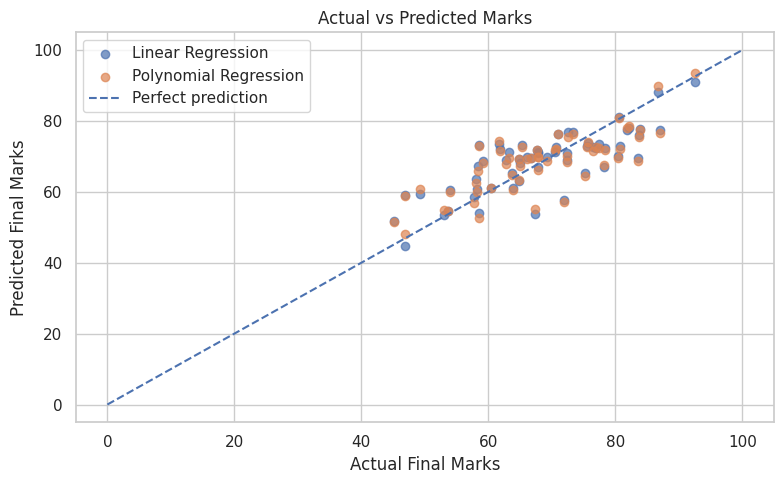

In [6]:
# Compare actual marks with both regression models for a sample of test records.
regression_comparison = pd.DataFrame({
    "Actual Final Marks": y_test.to_numpy(),
    "Linear Prediction": linear_predictions,
    "Polynomial Prediction": polynomial_predictions
}, index=y_test.index).sort_index()

display(regression_comparison.head(15).round(2))

plt.figure(figsize=(8, 5))
plt.scatter(y_test, linear_predictions, alpha=0.7, label="Linear Regression")
plt.scatter(y_test, polynomial_predictions, alpha=0.7, label="Polynomial Regression")
plt.plot([0, 100], [0, 100], linestyle="--", label="Perfect prediction")
plt.xlabel("Actual Final Marks")
plt.ylabel("Predicted Final Marks")
plt.title("Actual vs Predicted Marks")
plt.legend()
plt.tight_layout()
plt.show()

**Comparison:** Compare the MAE, RMSE, and R² values in the table. The model with lower MAE and RMSE and higher R² performs better on this held-out test set. Polynomial Regression can model nonlinear patterns, but it is not guaranteed to outperform Linear Regression.

## Question 3: Create a Logistic Regression model for Pass/Fail

Binary Logistic Regression Accuracy: 0.967

Classification report:
              precision    recall  f1-score   support

        Fail       1.00      0.50      0.67         4
        Pass       0.97      1.00      0.98        56

    accuracy                           0.97        60
   macro avg       0.98      0.75      0.82        60
weighted avg       0.97      0.97      0.96        60



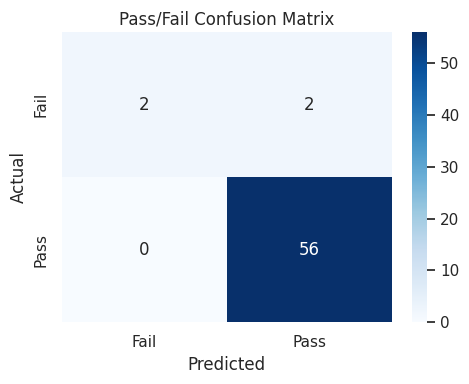

In [7]:
# Binary target: Pass if Final Marks >= 50, otherwise Fail.
y_binary = df["Pass/Fail"]

X_train_bin, X_test_bin, y_train_bin, y_test_bin = train_test_split(
    X, y_binary, test_size=0.20, random_state=RANDOM_STATE, stratify=y_binary
)

binary_logistic_model = Pipeline(steps=[
    ("scaler", StandardScaler()),
    ("logistic_regression", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
])

binary_logistic_model.fit(X_train_bin, y_train_bin)
binary_predictions = binary_logistic_model.predict(X_test_bin)

binary_accuracy = accuracy_score(y_test_bin, binary_predictions)
print(f"Binary Logistic Regression Accuracy: {binary_accuracy:.3f}")
print("\nClassification report:")
print(classification_report(y_test_bin, binary_predictions, zero_division=0))

binary_cm = confusion_matrix(y_test_bin, binary_predictions, labels=["Fail", "Pass"])
plt.figure(figsize=(5, 4))
sns.heatmap(binary_cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Fail", "Pass"], yticklabels=["Fail", "Pass"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Pass/Fail Confusion Matrix")
plt.tight_layout()
plt.show()

**Interpretation:** Logistic Regression estimates the probability of each class and assigns the class with the highest probability. The confusion matrix compares actual and predicted Pass/Fail labels. Accuracy is the proportion of correct predictions.

## Question 4: Multiclass Logistic Regression (Low, Medium, High)

Multiclass Logistic Regression Accuracy: 0.800

Classification report:
              precision    recall  f1-score   support

         Low       1.00      0.57      0.73        14
      Medium       0.77      0.94      0.85        35
        High       0.78      0.64      0.70        11

    accuracy                           0.80        60
   macro avg       0.85      0.72      0.76        60
weighted avg       0.82      0.80      0.79        60



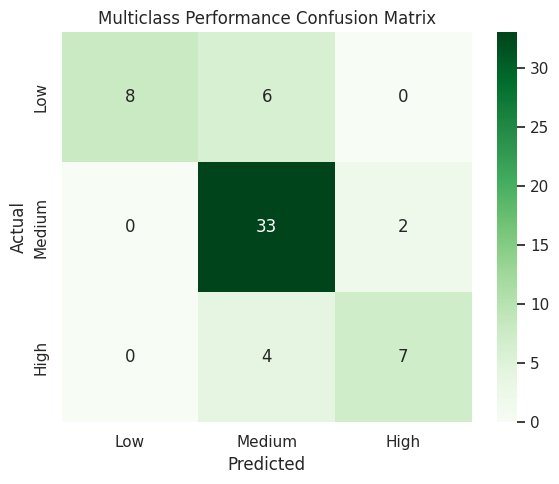

In [8]:
# Performance categories are based on final marks:
# Low < 60; Medium = 60 to 79.99; High >= 80.
y_multiclass = df["Performance"].astype(str)

X_train_multi, X_test_multi, y_train_multi, y_test_multi = train_test_split(
    X, y_multiclass, test_size=0.20, random_state=RANDOM_STATE, stratify=y_multiclass
)

multiclass_logistic_model = Pipeline(steps=[
    ("scaler", StandardScaler()),
    ("logistic_regression", LogisticRegression(
        max_iter=1000, random_state=RANDOM_STATE, solver="lbfgs"
    ))
])

multiclass_logistic_model.fit(X_train_multi, y_train_multi)
multiclass_predictions = multiclass_logistic_model.predict(X_test_multi)

multiclass_accuracy = accuracy_score(y_test_multi, multiclass_predictions)
print(f"Multiclass Logistic Regression Accuracy: {multiclass_accuracy:.3f}")
print("\nClassification report:")
print(classification_report(
    y_test_multi, multiclass_predictions,
    labels=["Low", "Medium", "High"], zero_division=0
))

multi_cm = confusion_matrix(
    y_test_multi, multiclass_predictions, labels=["Low", "Medium", "High"]
)
plt.figure(figsize=(6, 5))
sns.heatmap(multi_cm, annot=True, fmt="d", cmap="Greens",
            xticklabels=["Low", "Medium", "High"],
            yticklabels=["Low", "Medium", "High"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Multiclass Performance Confusion Matrix")
plt.tight_layout()
plt.show()

## Question 5: Compare model predictions with actual values

In [9]:
# Compare actual and predicted regression values.
regression_comparison = pd.DataFrame({
    "Actual Final Marks": y_test.to_numpy(),
    "Linear Regression Prediction": linear_predictions,
    "Polynomial Regression Prediction": polynomial_predictions
}, index=y_test.index).sort_index()

print("Regression: actual vs predicted (first 15 test students)")
display(regression_comparison.head(15).round(2))

# Compare actual and predicted binary labels.
binary_comparison = pd.DataFrame({
    "Actual Pass/Fail": y_test_bin,
    "Predicted Pass/Fail": binary_predictions
})
binary_comparison["Correct?"] = (
    binary_comparison["Actual Pass/Fail"] == binary_comparison["Predicted Pass/Fail"]
)
print("Binary classification: actual vs predicted (first 15 test students)")
display(binary_comparison.head(15))

# Compare actual and predicted multiclass labels.
multiclass_comparison = pd.DataFrame({
    "Actual Performance": y_test_multi,
    "Predicted Performance": multiclass_predictions
})
multiclass_comparison["Correct?"] = (
    multiclass_comparison["Actual Performance"] == multiclass_comparison["Predicted Performance"]
)
print("Multiclass classification: actual vs predicted (first 15 test students)")
display(multiclass_comparison.head(15))

Regression: actual vs predicted (first 15 test students)


,Actual Final Marks,Linear Regression Prediction,Polynomial Regression Prediction
5,58.49,73.15,72.99
7,66.74,69.42,69.43
9,76.46,72.58,71.58
17,63.20,71.11,69.54
24,65.37,73.10,72.58
25,75.24,65.30,64.38
33,83.76,76.13,75.53
42,52.98,53.51,54.74
45,67.87,71.36,69.70
46,58.27,60.86,59.98


Binary classification: actual vs predicted (first 15 test students)


,Actual Pass/Fail,Predicted Pass/Fail,Correct?
284,Pass,Pass,True
109,Fail,Pass,False
64,Pass,Pass,True
198,Pass,Pass,True
249,Pass,Pass,True
173,Fail,Pass,False
87,Pass,Pass,True
274,Pass,Pass,True
144,Pass,Pass,True
46,Pass,Pass,True


Multiclass classification: actual vs predicted (first 15 test students)


,Actual Performance,Predicted Performance,Correct?
143,Medium,Medium,True
174,High,High,True
84,High,High,True
112,High,High,True
223,Low,Medium,False
96,High,Medium,False
76,Medium,Medium,True
164,Low,Low,True
166,Medium,Medium,True
150,High,High,True


In [10]:
# Overall model comparison using appropriate evaluation metrics.
model_summary = pd.DataFrame({
    "Model": [
        "Multivariate Linear Regression",
        "Polynomial Regression (degree 2)",
        "Binary Logistic Regression (Pass/Fail)",
        "Multiclass Logistic Regression (Low/Medium/High)"
    ],
    "Primary Metric": ["R²", "R²", "Accuracy", "Accuracy"],
    "Score": [linear_r2, polynomial_r2, binary_accuracy, multiclass_accuracy]
})
display(model_summary.round(3))

print("Correct binary predictions:", int(binary_comparison["Correct?"].sum()), "out of", len(binary_comparison))
print("Correct multiclass predictions:", int(multiclass_comparison["Correct?"].sum()), "out of", len(multiclass_comparison))

,Model,Primary Metric,Score
0,Multivariate Linear Regression,R²,0.615
1,Polynomial Regression (degree 2),R²,0.614
2,Binary Logistic Regression (Pass/Fail),Accuracy,0.967
3,Multiclass Logistic Regression (Low/Medium/High),Accuracy,0.800


Correct binary predictions: 58 out of 60
Correct multiclass predictions: 48 out of 60


## Final Conclusion

1. **Multivariate Linear Regression:** Used four independent variables to predict the continuous Final Marks value.
2. **Polynomial Regression:** Added degree-2 polynomial terms and compared its MAE, RMSE, and R² with the linear model on the same test records.
3. **Binary Logistic Regression:** Predicted Pass or Fail using a threshold of 50 marks.
4. **Multiclass Logistic Regression:** Classified students as Low, Medium, or High using the stated mark ranges.
5. **Actual vs predicted comparison:** Displayed prediction tables and classification confusion matrices, and calculated regression and classification metrics.

**Evaluation note:** The dataset is synthetic and designed for demonstrating the requested algorithms. Results demonstrate model workflow and evaluation; they should not be interpreted as findings about a real student population.

## Optional: Download the generated dataset

Run this cell if you also want a CSV copy of the synthetic dataset.

In [11]:
df.to_csv("student_performance_dataset.csv", index=False)
print("Saved student_performance_dataset.csv")
try:
    from google.colab import files
    files.download("student_performance_dataset.csv")
except ImportError:
    print("CSV saved in the current notebook working directory.")

Saved student_performance_dataset.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>